In [1]:
!pip install kagglehub


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip


# 데이터 불러오기

In [35]:
import os
import torch
import pandas as pd
import kagglehub
from torchvision import datasets
from torch.utils.data import DataLoader
from torchvision.transforms import v2
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from PIL import Image
from collections import Counter

In [ ]:
# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")
print("Dataset path:", path)

100%|██████████| 2.29G/2.29G [01:19<00:00, 31.0MB/s]

Extracting files...


Dataset path: /Users/yundong-ug/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2


In [25]:
# GPU 설정
device = torch.device("mps" if torch.mps.is_available() else "cpu")
print(device)

mps


In [4]:
train_dir = os.path.join(path, "chest_xray", "train")
val_dir = os.path.join(path, "chest_xray", "val")
test_dir = os.path.join(path, "chest_xray", "test")

# transform 전에 원본 데이터 확인

In [ ]:
train_dataset = datasets.ImageFolder(train_dir)

'/Users/yundong-ug/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/train'

In [26]:
path, label = train_dataset.samples[0]

with Image.open(path) as img:
    print(path)
    print(img.size)  # (가로 픽셀, 세로 픽셀)

/Users/yundong-ug/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/train/NORMAL/IM-0115-0001.jpeg
(2090, 1858)


In [ ]:
sizes = Counter()
for path, _ in train_dataset.samples:
    with Image.open(path) as img:
        sizes[img.size] += 1

train_data_size_table = pd.DataFrame(
    [(width, height, count) for (width, height), count in sizes.items()],
    columns=["width", "height", "count"]
).sort_values("count", ascending=False).reset_index(drop=True)

<class 'pandas.DataFrame'>
RangeIndex: 4366 entries, 0 to 4365
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   width   4366 non-null   int64
 1   height  4366 non-null   int64
 2   count   4366 non-null   int64
dtypes: int64(3)
memory usage: 102.5 KB


In [65]:
train_data_size_table.describe()

,width,height,count
count,4366.000000,4366.000000,4366.000000
mean,1354.620705,1005.840357,1.194686
std,369.080580,394.074698,0.536954
min,384.000000,127.000000,1.000000
25%,1080.000000,712.000000,1.000000
50%,1336.000000,955.000000,1.000000
75%,1600.000000,1248.000000,1.000000
max,2916.000000,2663.000000,7.000000


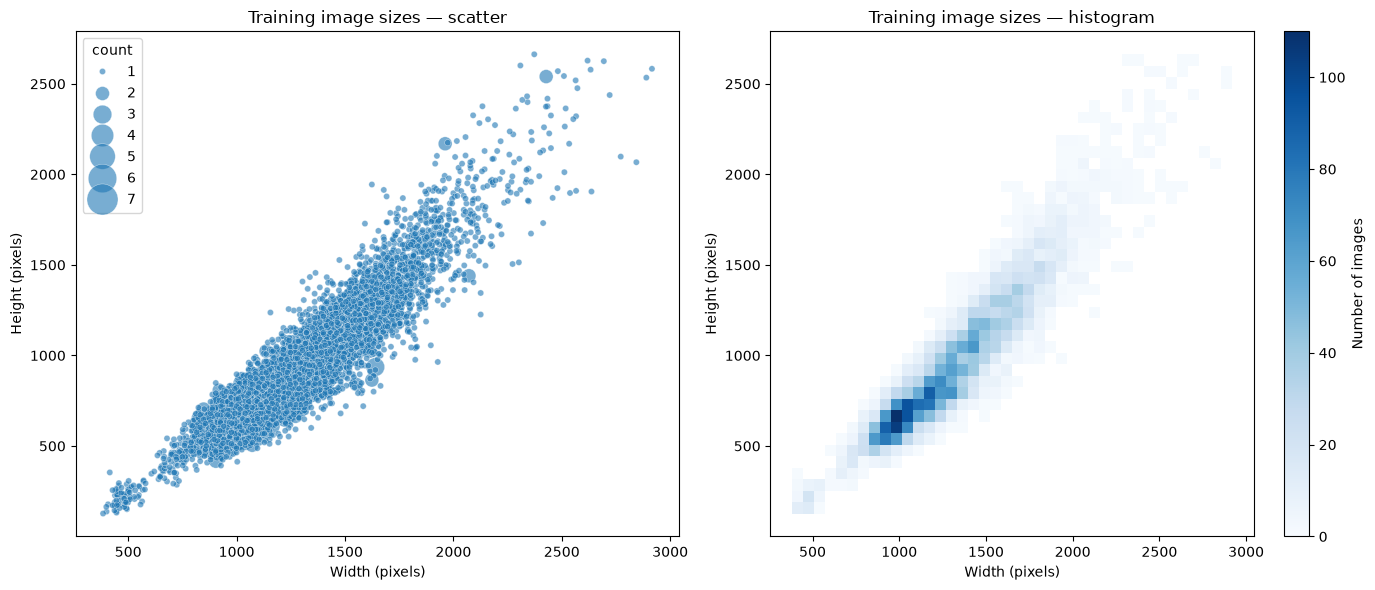

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sns.scatterplot(
    data=train_data_size_table,
    x="width",
    y="height",
    size="count",
    sizes=(20, 500),
    alpha=0.6,
    legend="brief",
    ax=axes[0],
)
axes[0].set_title("Training image sizes — scatter")
axes[0].set_xlabel("Width (pixels)")
axes[0].set_ylabel("Height (pixels)")

sns.histplot(
    data=train_data_size_table,
    x="width",
    y="height",
    weights="count",
    bins=40,
    cmap="Blues",
    cbar=True,
    cbar_kws={"label": "Number of images"},
    ax=axes[1],
)
axes[1].set_title("Training image sizes — histogram")
axes[1].set_xlabel("Width (pixels)")
axes[1].set_ylabel("Height (pixels)")

fig.tight_layout()
plt.show()

In [39]:
class_counts = (
    pd.Series(train_dataset.targets)
    .map(dict(enumerate(train_dataset.classes)))
    .value_counts()
)

class_table = pd.DataFrame({
    "class": class_counts.index,
    "count": class_counts.values,
    "percent": class_counts.values / class_counts.sum() * 100
})

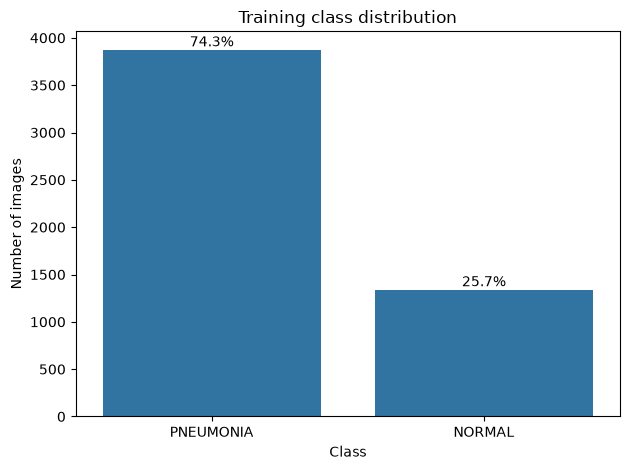

In [40]:
ax = sns.barplot(data=class_table, x="class", y="count")

for bar, percent in zip(ax.patches, class_table["percent"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{percent:.1f}%",
        ha="center",
        va="bottom"
    )

ax.set(xlabel="Class", ylabel="Number of images", title="Training class distribution")
plt.tight_layout()
plt.show()

In [41]:
BASELINE = 0.743

print("baseline(찍기)", BASELINE)

baseline(찍기) 0.743


In [60]:
transforms = v2.Compose(
    [
        v2.Resize((224, 224)),
        v2.ToImage(),
        v2.ToDtype(dtype=torch.float32, scale=True),
        # v2.Normalize(mean=[0.5], std=[0.5]),
    ]
)

# 데이터셋 로드
train_dataset = datasets.ImageFolder(train_dir, transform=transforms)

# DataLoader 생성
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)

# 클래스 확인
class_names = train_dataset.classes
print("Class names:", class_names)

train_dataset

Class names: ['NORMAL', 'PNEUMONIA']


Dataset ImageFolder
    Number of datapoints: 5216
    Root location: /Users/yundong-ug/.cache/kagglehub/datasets/paultimothymooney/chest-xray-pneumonia/versions/2/chest_xray/train
    StandardTransform
Transform: Compose(
                 Resize(size=[224, 224], interpolation=bilinear, antialias=True)
                 ToImage()
                 ToDtype(scale=True)
           )

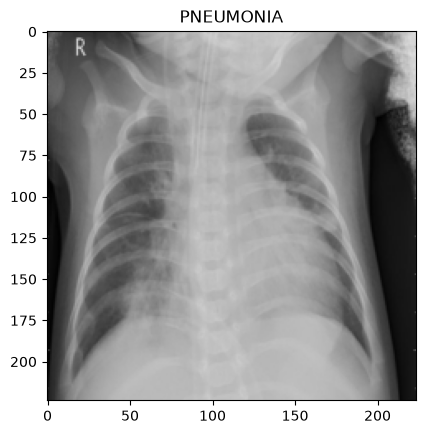

In [61]:
# 데이터 로더에서 배치 가져오기 (train)
images, labels = next(iter(train_loader))

# 이미지를 디스플레이
def imshow(img, title):
    # img = img / 2 + 0.5  # 정규화 복원
    npimg = img.cpu().numpy()
    # npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.title(title)
    plt.show()

# 첫 번째 배치의 첫 번째 이미지 시각화
imshow(images[0], title=class_names[labels[0]])

In [62]:
# 데이터 전처리 정의
data_transforms = {
    'train': v2.Compose([
        v2.Resize((224, 224)),                # 이미지 크기 조정
        v2.RandomCrop((200, 200)),           # 랜덤 크롭 (200x200)
        v2.RandomRotation(20),              # 랜덤 회전 (-20도 ~ 20도)
        v2.ToTensor(),                       # 텐서로 변환
        v2.Normalize([0.5], [0.5])           # 정규화
    ]),
    'val': v2.Compose([
        v2.Resize((224, 224)),               # 이미지 크기 조정
        v2.ToTensor(),                       # 텐서로 변환
        v2.Normalize([0.5], [0.5])           # 정규화
    ]),
    'test': v2.Compose([
        v2.Resize((224, 224)),               # 이미지 크기 조정
        v2.ToTensor(),                       # 텐서로 변환
        v2.Normalize([0.5], [0.5])           # 정규화
    ])
}

In [63]:
# 데이터셋 로드
train_dataset = datasets.ImageFolder(train_dir, transform=data_transforms['train'])
val_dataset = datasets.ImageFolder(val_dir, transform=data_transforms['val'])
test_dataset = datasets.ImageFolder(test_dir, transform=data_transforms['test'])

# DataLoader 생성
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(f"Number of training samples: {len(train_dataset)}")
print(f"Number of validation samples: {len(val_dataset)}")
print(f"Number of test samples: {len(test_dataset)}")

Number of training samples: 5216
Number of validation samples: 16
Number of test samples: 624


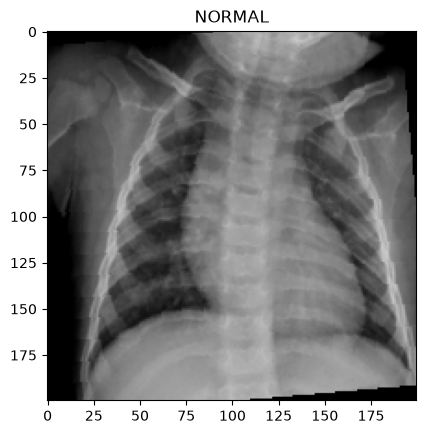

In [64]:
# 데이터 로더에서 배치 가져오기 (train)
images, labels = next(iter(train_loader))

# 이미지를 디스플레이
def imshow(img, title):
    img = img / 2 + 0.5  # 정규화 복원
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.title(title)
    plt.show()

# 첫 번째 배치의 첫 번째 이미지 시각화
imshow(images[0], title=class_names[labels[0]])